
# Heavy Machinery Price Prediction

## 1.Project Overview
The objective of this project is to predict the sale prices of heavy machinery using historical data and machine learning regression models.

The project explores the dataset, develops relevant features, compares multiple regression algorithms, and evaluates model performance using appropriate regression metrics.


## 2.Importing libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path



sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)



## 3.Data Loading and Initial Inspection

We load the training, test, and metadata datasets to understand
their structure, feature availability, and suitability for
the subsequent exploratory data analysis.


In [2]:
train=pd.read_csv("Data/train.csv")
test=pd.read_csv("Data/test.csv")


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3988\197936491.py:1: DtypeWarning: Columns (0: col18, 1: col19) have mixed types. Specify dtype option on import or set low_memory=False.
  train=pd.read_csv("Data/train.csv")



### 3.1 Dataset Structure and Data Quality

We examine the data types and missing values in the training and test datasets. This helps identify columns that may require preprocessing before model training.


In [3]:

# Inspect column names and data types
train.info()

# Check missing values
missing_values = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

missing_values = missing_values[missing_values["Missing Count"] > 0]
display(missing_values.sort_values("Missing Percentage", ascending=False))

# Check duplicate rows
print("Duplicate rows:", train.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  str    
 5   VendorPartnerID            138701 non-null  str    
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   str    
 9   TransactionDate            138701 non-null  str    
 10  Spec_FullDescriptor        138701 non-null  str    
 11  Spec_BaseClass             138701 non-null  str    
 12  Spec_SubClass              101716 non-null  str    
 13  Spec_ReleaseSeries         32896 non-nul

,Missing Count,Missing Percentage
col18,138635,99.952416
col19,138635,99.952416
col4,128320,92.515555
col5,128320,92.515555
col28,123742,89.214930
col27,123742,89.214930
col30,119829,86.393753
col29,119829,86.393753
col14,115296,83.125572
col11,115296,83.125572


Duplicate rows: 0



## 4. Exploratory Data Analysis (EDA)

In this section, we explore the target variable and available features to understand their distributions, identify data-quality issues, and investigate patterns that may help predict machinery sale prices.



###     4.1 Missing Value Analysis

Several features contain missing observations. We quantify missingness to distinguish between relatively complete features and those with substantial gaps before deciding on an appropriate preprocessing strategy.


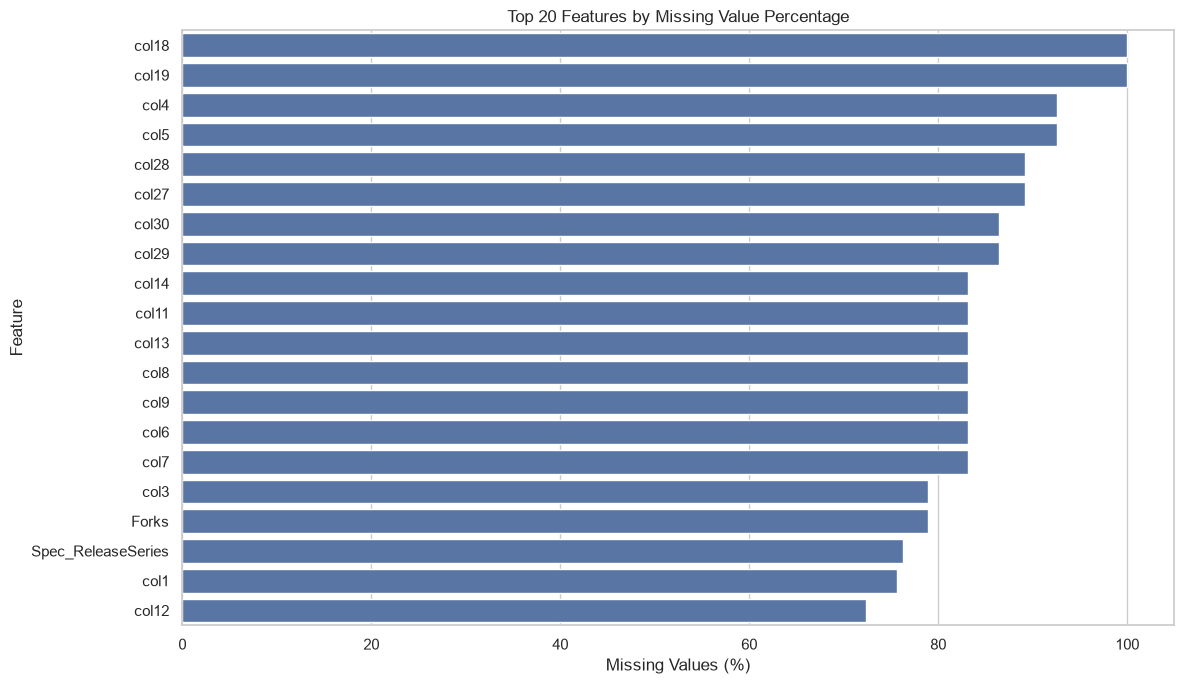

In [4]:
missing_top = missing_values.sort_values(
    "Missing Percentage", ascending=False
).head(20)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=missing_top.reset_index(),
    x="Missing Percentage",
    y="index"
)

plt.title("Top 20 Features by Missing Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()




**Observations:**

The missing-value analysis reveals substantial missingness in several features. `col18` and `col19` have nearly 100% missing values, while multiple other columns have more than 80% missingness.

These findings highlight the need to investigate feature completeness before preprocessing. However, no columns are removed at this stage; their usefulness will be evaluated before making preprocessing decisions.


### 4.2 Target Variable Distribution

We examine the distribution of `TargetValue` to understand the spread of machinery sale prices, identify potential skewness, and determine whether a target transformation may be worth exploring during model development.


count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64

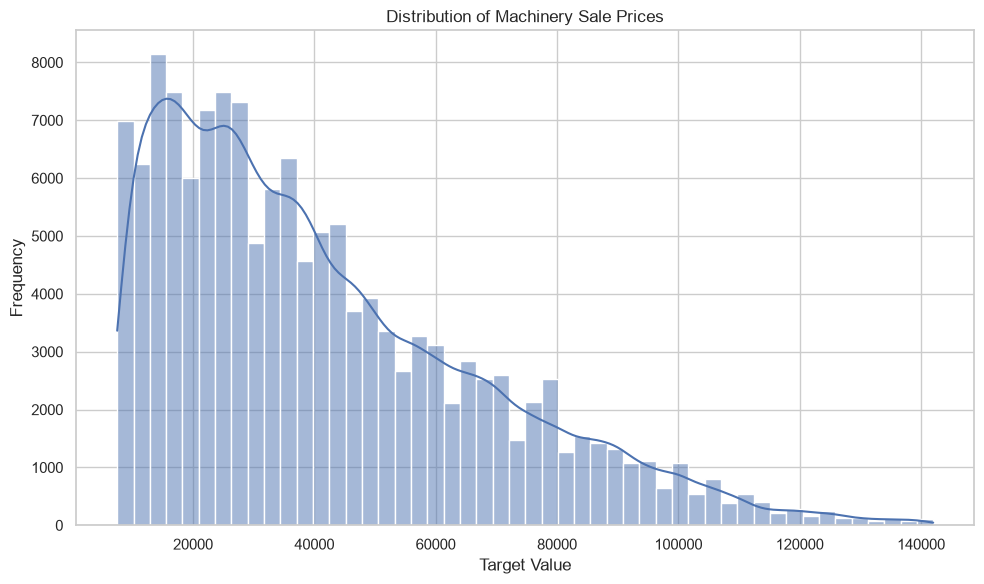

In [5]:

display(train["TargetValue"].describe())

plt.figure(figsize=(10, 6))
sns.histplot(data=train, x="TargetValue", bins=50, kde=True)

plt.title("Distribution of Machinery Sale Prices")
plt.xlabel("Target Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



**Observations:**

- The target variable is positively skewed, with most machinery sale prices concentrated in the lower price range and a long tail extending toward higher values.
- The mean sale price (approximately 41,521) is higher than the median (35,000), supporting the presence of right skewness.
- Sale prices range from 7,500 to 142,000, indicating substantial variation in the target variable.
- The 50th percentile is 35,000, while the 75th percentile is 57,000, showing that the upper portion of the price distribution extends considerably beyond the median.

**Implications for modeling:**

The right-skewed distribution may affect model performance, so we will compare models trained on the original target values with models using a log-transformed target.


### 4.3 Target Variable Outlier Analysis

A box plot helps visualize the median, interquartile range, and potential outliers in machinery sale prices. We use it to understand the spread of the target variable and identify extreme observations for further investigation.


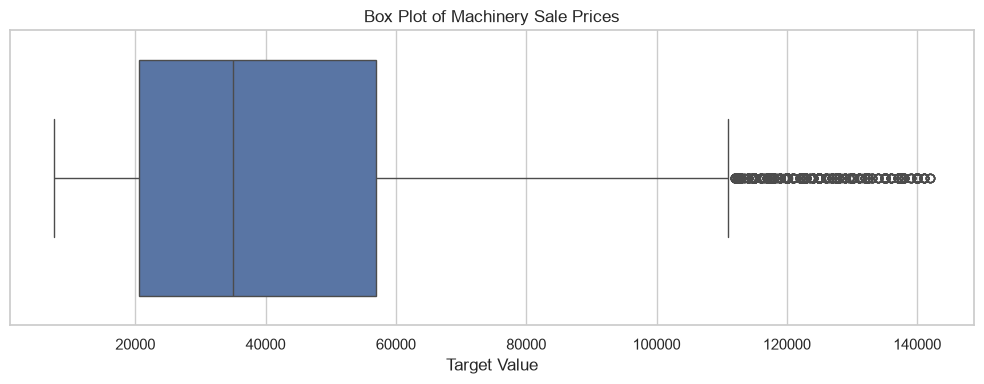

In [6]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["TargetValue"])

plt.title("Box Plot of Machinery Sale Prices")
plt.xlabel("Target Value")
plt.tight_layout()
plt.show()



**Observations:**

- The median sale price is approximately 35,000, as shown by the line inside the box.
- The middle 50% of sale prices lie between approximately 20,500 and 57,000.
- Several observations above the upper whisker are identified as potential outliers, with prices extending beyond 140,000.

These high-price observations may represent expensive machinery rather than incorrect data. We will retain the original data during EDA and investigate whether these observations affect model performance during model development.



### 4.4 Numerical Feature Analysis

We examine the numerical features to understand their distributions and identify variables that may help explain differences in machinery sale prices.


In [7]:
numerical_features = train.select_dtypes(include="number").columns.tolist()

# Exclude the target variable from the feature list
numerical_features.remove("TargetValue")

print("Number of numerical features:", len(numerical_features))
display(train[numerical_features].describe().T)


Number of numerical features: 5


,count,mean,std,min,25%,50%,75%,max
TransactionID,138701.0,2.186276e+06,1.128497e+06,1139309.0,1465754.0,1751884.0,2372139.0,6333410.0
AssetID,138701.0,1.204814e+06,5.287376e+05,8.0,1007930.0,1246956.0,1495817.0,2478476.0
ProductConfigID,138701.0,7.286422e+03,7.542422e+03,39.0,1693.0,3852.0,11873.0,37209.0
ManufactureYear,138701.0,1.891641e+03,3.069920e+02,1001.0,1990.0,1998.0,2004.0,2015.0
OperationalHoursMeter,82058.0,4.553719e+03,2.792204e+04,0.0,0.0,1620.0,5001.0,1729600.0



**Observations:**

- The dataset contains five numerical columns apart from the target variable.
- `TransactionID`, `AssetID`, and `ProductConfigID` are identifier-like features whose usefulness for prediction needs further investigation.
- `ManufactureYear` may help explain differences in machinery prices.
- `OperationalHoursMeter` has substantial missing data and a wide range of values.

These observations will guide our later feature analysis and preprocessing decisions.



#### 4.4.1 Distribution of Numerical Features

We examine the distributions of `ManufactureYear` and `OperationalHoursMeter` to understand the age and usage of machines in the dataset. These characteristics may help explain differences in machinery sale prices.


In [8]:
manufacture_year_counts = train["ManufactureYear"].value_counts().sort_index()

display(manufacture_year_counts.head(10))
display(manufacture_year_counts.tail(10))

ManufactureYear
1001    14719
1920       13
1921        7
1949        1
1951        2
1952        3
1953        3
1954        2
1955        1
1957        8
Name: count, dtype: int64

ManufactureYear
2006    10895
2007     7133
2008     2657
2009      870
2010      113
2011       32
2012        6
2013        1
2014        1
2015        1
Name: count, dtype: int64

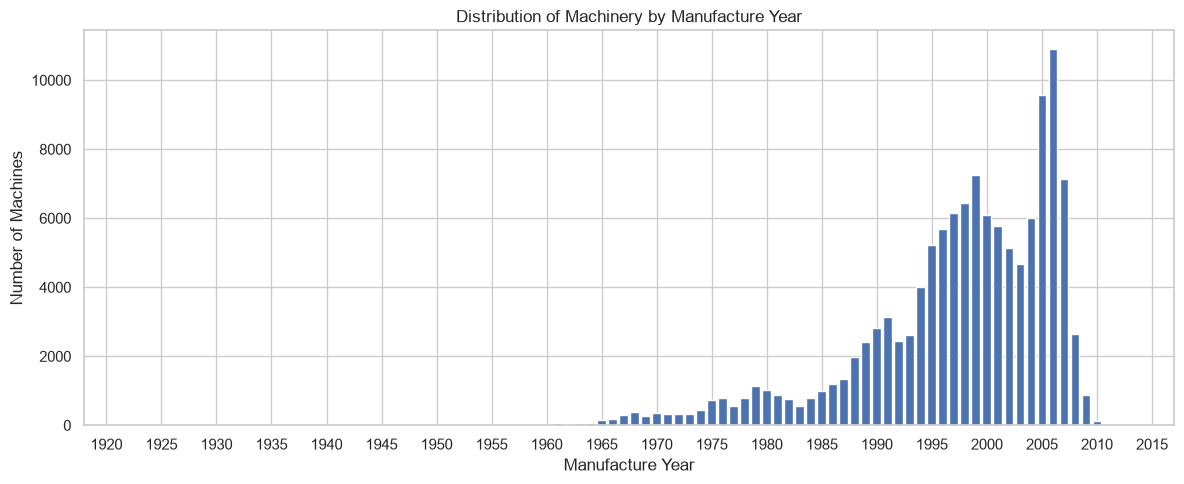

In [9]:
manufacture_year_counts = train.loc[
    train["ManufactureYear"] >= 1920,
    "ManufactureYear"
].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    manufacture_year_counts.index,
    manufacture_year_counts.values,
    width=0.8
)

ax.set_title("Distribution of Machinery by Manufacture Year")
ax.set_xlabel("Manufacture Year")
ax.set_ylabel("Number of Machines")
ax.set_xlim(1918, 2017)
ax.set_xticks(range(1920, 2016, 5))

plt.tight_layout()
plt.show()

**Observations:**

- The number of machines in the dataset generally increases from the 1960s onward, with a substantial concentration of records from the 1990s to the mid-2000s.
- The highest number of records appears around 2006, followed by a noticeable decline in subsequent years.
- Very few machines are recorded for the earlier manufacturing years, so their bars appear much shorter on the graph.
- Manufacturing year may be a useful feature for price prediction, as it can help capture differences associated with a machine's age.

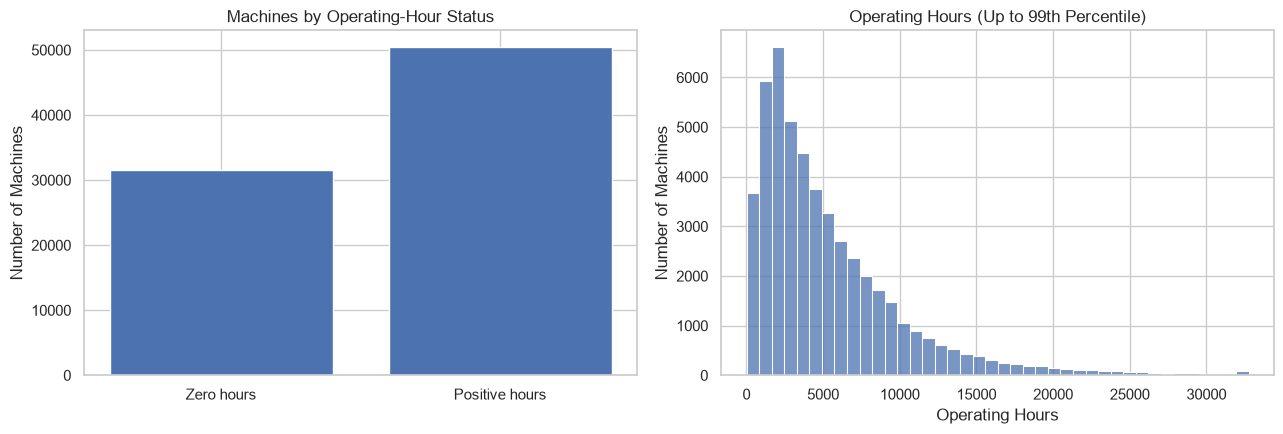

In [10]:
operational_hours = train["OperationalHoursMeter"].dropna()

zero_count = (operational_hours == 0).sum()
positive_hours = operational_hours[operational_hours > 0]
p99 = positive_hours.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Zero versus positive operating-hour readings
axes[0].bar(
    ["Zero hours", "Positive hours"],
    [zero_count, len(positive_hours)]
)
axes[0].set_title("Machines by Operating-Hour Status")
axes[0].set_ylabel("Number of Machines")

# Distribution of positive readings, excluding only the top 1% from the view
sns.histplot(
    positive_hours[positive_hours <= p99],
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Operating Hours (Up to 99th Percentile)")
axes[1].set_xlabel("Operating Hours")
axes[1].set_ylabel("Number of Machines")

plt.tight_layout()
plt.show()



**Observations:**

- The dataset contains more machines with positive operating-hour readings than machines with zero readings.
- The distribution of positive operating hours is right-skewed, with most machines having relatively low operating-hour readings and progressively fewer machines at higher values.
- Most positive readings are concentrated below approximately 10,000 hours, although some machines have substantially higher readings.
- Zero operating-hour readings may represent unused machines or missing/unrecorded meter readings. Their meaning needs further investigation before preprocessing.

These findings suggest that operating hours may help explain differences in machinery prices. We will investigate this relationship in the subsequent analysis.

#### 4.4.2 Distribution of the Target Variable

We examine the distribution of `TargetValue` to understand the typical transaction value of machinery, the variability in values, and the degree of skewness. These characteristics will help us assess the target distribution and determine whether a transformation may be beneficial during model development.

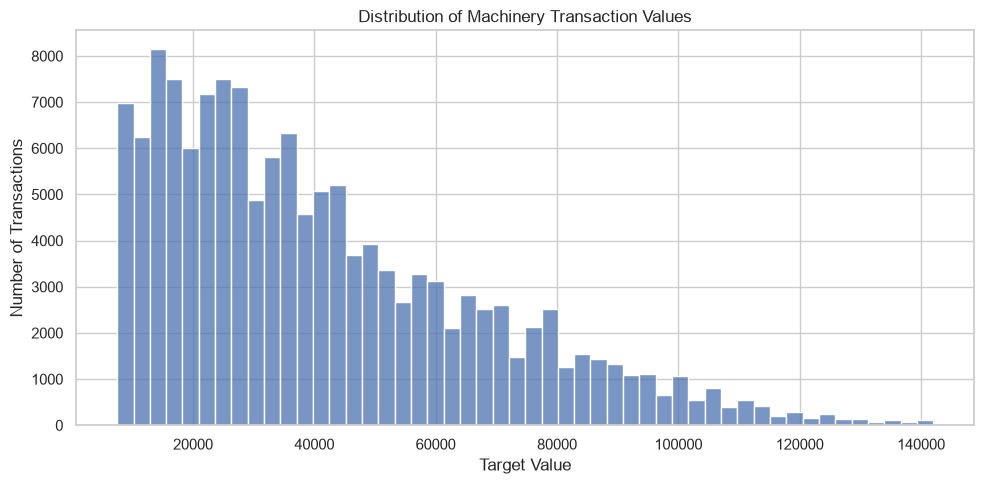

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train,
    x="TargetValue",
    bins=50
)

plt.title("Distribution of Machinery Transaction Values")
plt.xlabel("Target Value")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

**Observations**

- The distribution of `TargetValue` is right-skewed, with most transactions concentrated in the lower value ranges.
- Transaction frequency generally decreases as the target value increases, with relatively few transactions above 100,000.
- The wide range of target values indicates substantial variation in machinery transaction values.


#### 4.4.3 Relationship Between Numerical Features and Target Value

We examine how `ManufactureYear` and `OperationalHoursMeter` relate to `TargetValue` to see whether machine age and usage are associated with differences in transaction values.

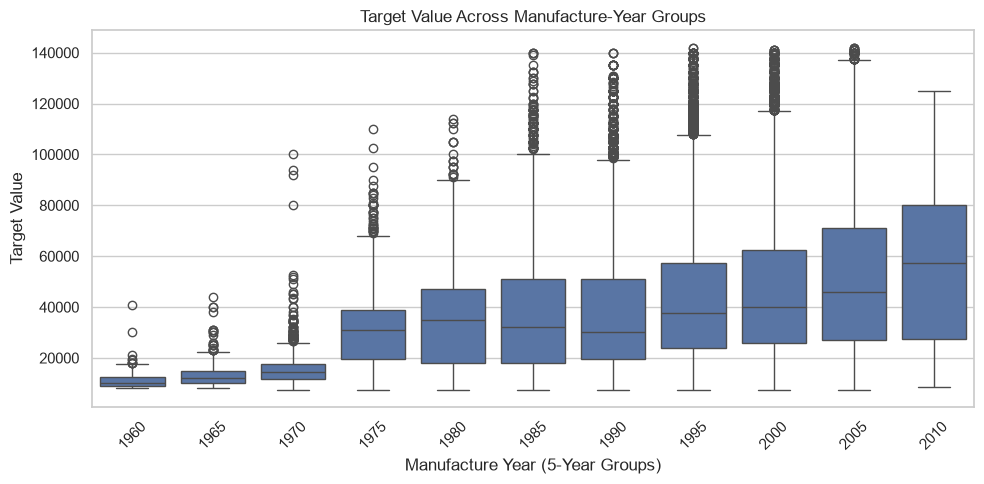

In [12]:
plt.figure(figsize=(10, 5))

train_filtered = train[
    (train["ManufactureYear"] >= 1960) &
    (train["ManufactureYear"] <= 2010)
].copy()

train_filtered["YearGroup"] = (
    (train_filtered["ManufactureYear"] // 5) * 5
)

sns.boxplot(
    data=train_filtered,
    x="YearGroup",
    y="TargetValue"
)

plt.title("Target Value Across Manufacture-Year Groups")
plt.xlabel("Manufacture Year (5-Year Groups)")
plt.ylabel("Target Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:**

- The target value generally increases with the manufacture year, suggesting that newer machines tend to have higher transaction values.
- Older machines are concentrated in the lower target-value range, while machines manufactured during the 1990s and 2000s show a much wider range of values.
- There is considerable variation in target values even among machines manufactured in the same year, so manufacture year alone cannot explain the differences in machine prices.

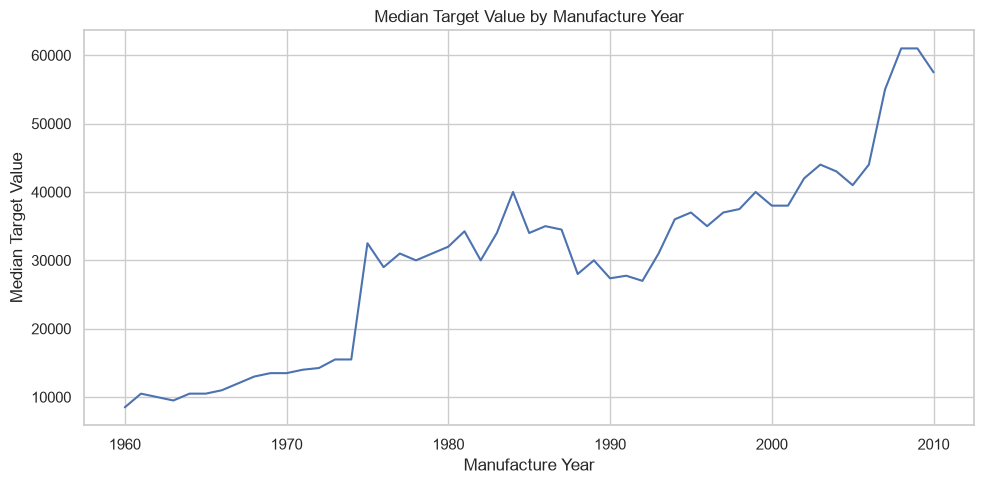

In [13]:
yearly_median = (
    train.loc[train["ManufactureYear"].between(1960, 2010)]
    .groupby("ManufactureYear")["TargetValue"]
    .median()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=yearly_median.index,
    y=yearly_median.values
)

plt.title("Median Target Value by Manufacture Year")
plt.xlabel("Manufacture Year")
plt.ylabel("Median Target Value")
plt.tight_layout()
plt.show()

**Observations**

- Most transactions are concentrated among machines with relatively low operating hours.
- Transaction values vary considerably at similar operating-hour levels.
- Higher operating hours do not show a clear, consistent relationship with lower transaction values in this plot.
- Operational hours alone may not be sufficient to explain differences in transaction values.

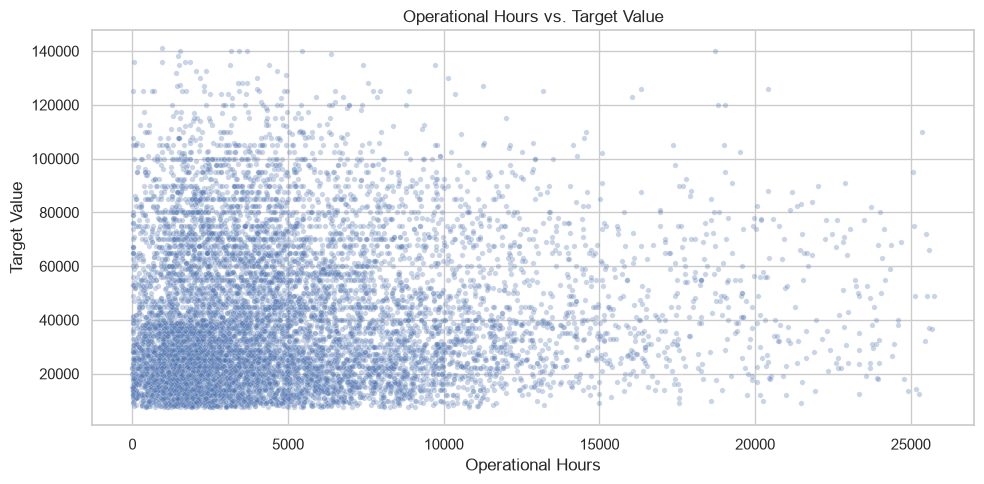

In [14]:
hours_data = train.loc[
    train["OperationalHoursMeter"].notna()
    & (train["OperationalHoursMeter"] > 0)
    & (train["OperationalHoursMeter"] <= train["OperationalHoursMeter"].quantile(0.99))
]

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=hours_data.sample(n=min(10000, len(hours_data)), random_state=42),
    x="OperationalHoursMeter",
    y="TargetValue",
    alpha=0.3,
    s=15
)

plt.title("Operational Hours vs. Target Value")
plt.xlabel("Operational Hours")
plt.ylabel("Target Value")
plt.tight_layout()
plt.show()

**Observations**

- Most transactions involve machines with fewer than 10,000 operating hours.
- Transaction values vary widely among machines with similar operating hours.
- Machines with higher operating hours can still have relatively high transaction values; the plot does not show a clear downward trend.
- Operating hours may help predict transaction value, but their effect likely depends on other factors, such as manufacture year and machine specifications.

### 4.5 Categorical Feature Analysis

Categorical features describe the type, configuration, classification, and other characteristics of each machine. We will examine their distributions to understand which categories are common and identify features that may help explain differences in machinery transaction values.

In [15]:
categorical_cols = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical features:", len(categorical_cols))
print("\nCategorical features:")
print(categorical_cols)

Number of categorical features: 44

Categorical features:
['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'TransactionDate', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18', 'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3988\4036003710.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train.select_dtypes(


In [16]:
category_counts = train[categorical_cols].nunique().sort_values(ascending=False)

print(category_counts.to_string())

TransactionDate              3676
Spec_FullDescriptor          3505
Spec_BaseClass               1249
Spec_SubClass                 147
Spec_VariantModifier          132
Spec_ReleaseSeries            113
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col22                          27
col21                          18
col15                          15
col10                          11
col27                           9
DrivetrainType                  8
DataOriginCode                  6
col7                            6
AssetScaleFactor                6
InventoryGroupDescription       6
InventoryGroupCategory          6
col28                           5
col1                            4
col12                           4
UtilizationTier                 3
col3                            3
col8                            3
col23                           3
CabinType                       3
col25                           3
col24         

#### 4.5.1 Distribution of Utilization Tiers

Utilization tier indicates a machine's usage classification. Examining its distribution helps us understand how transactions are represented across the available tiers.

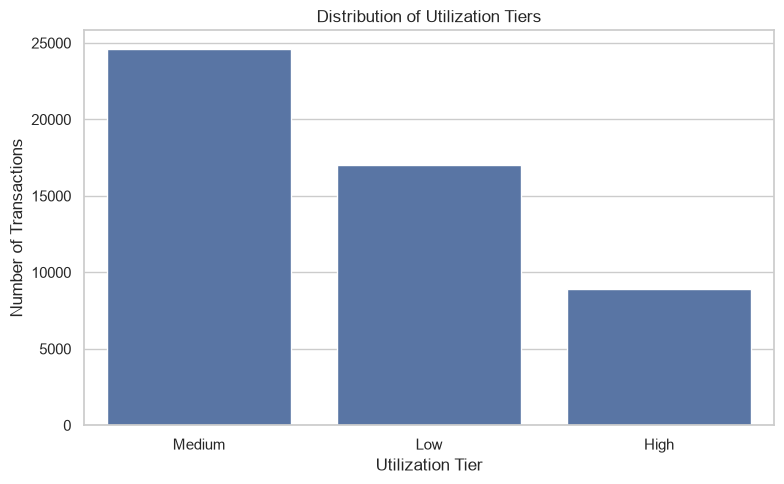

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="UtilizationTier",
    order=train["UtilizationTier"].value_counts().index
)

plt.title("Distribution of Utilization Tiers")
plt.xlabel("Utilization Tier")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

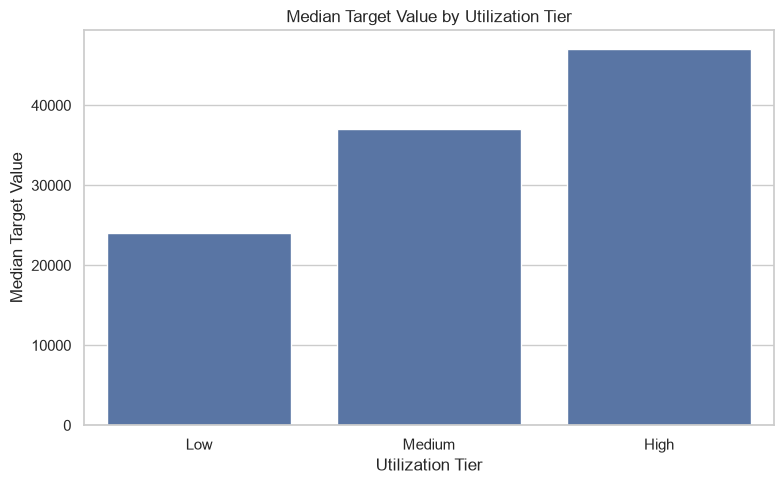

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="UtilizationTier",
    y="TargetValue",
    order=["Low", "Medium", "High"],
    estimator="median",
    errorbar=None
)

plt.title("Median Target Value by Utilization Tier")
plt.xlabel("Utilization Tier")
plt.ylabel("Median Target Value")
plt.tight_layout()
plt.show()

**Observations:**
- Machines in the High utilization tier have the highest median transaction value, followed by Medium and Low tiers.
- The consistent increase in median target value suggests an association between utilization tier and machinery prices.
- `UtilizationTier` appears worth retaining for model building, although its predictive contribution will be evaluated during model validation.

#### 4.5.2 Transaction Year Analysis

We examine how median machinery transaction values vary across years to identify any time-related patterns in the dataset.

In [19]:
print("Data type:", train["TransactionDate"].dtype)

print("\nMissing values:", train["TransactionDate"].isna().sum())

print("\nSample values:")
print(train["TransactionDate"].head(10))

print("\nNumber of unique dates:", train["TransactionDate"].nunique())

Data type: str

Missing values: 0

Sample values:
0    2005-03-26
1    2009-12-18
2    2005-08-26
3    2006-11-17
4    2010-08-27
5    2008-08-09
6    2009-08-21
7    2006-10-20
8    2007-01-26
9    2007-01-03
Name: TransactionDate, dtype: str

Number of unique dates: 3676


In [20]:
transaction_dates = pd.to_datetime(train["TransactionDate"], errors="coerce")

print("Earliest transaction date:", transaction_dates.min())
print("Latest transaction date:", transaction_dates.max())
print("Invalid dates:", transaction_dates.isna().sum())

Earliest transaction date: 1990-01-31 00:00:00
Latest transaction date: 2013-04-28 00:00:00
Invalid dates: 0


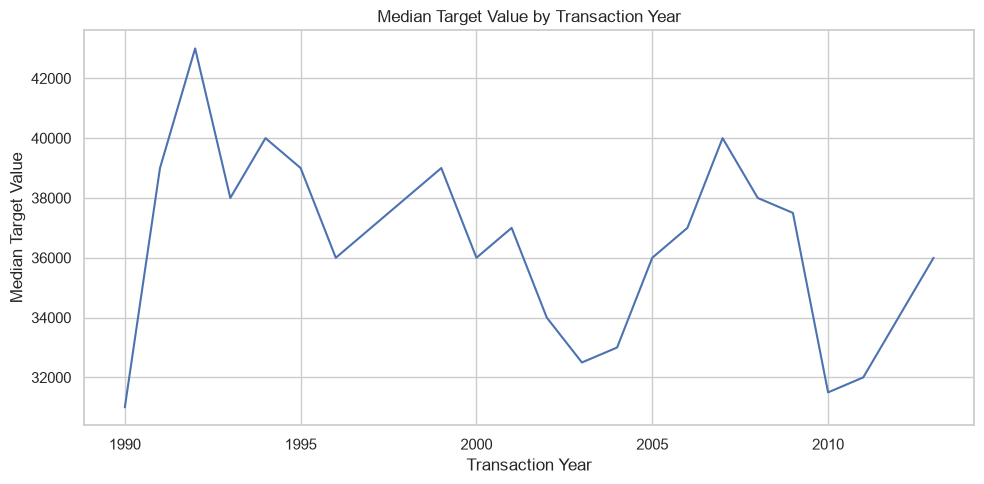

In [21]:
date_analysis = pd.DataFrame({
    "TransactionYear": transaction_dates.dt.year,
    "TargetValue": train["TargetValue"]
})

yearly_prices = (
    date_analysis.groupby("TransactionYear")["TargetValue"]
    .median()
)

plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly_prices.index, y=yearly_prices.values)

plt.title("Median Target Value by Transaction Year")
plt.xlabel("Transaction Year")
plt.ylabel("Median Target Value")
plt.tight_layout()
plt.show()

**Observations:**
- Median transaction values fluctuate considerably across years, with no consistent upward or downward trend.
- The median value drops noticeably around 2003–2004 and 2010, with recoveries in the intervening years.
- Transaction year alone does not explain these fluctuations; differences in the types and condition of machines sold may also contribute.

#### 4.5.3 High-Cardinality Categorical Features

Some categorical features contain many distinct values. Examining their cardinality helps us understand which columns may require special handling during preprocessing.

In [22]:
high_cardinality = (
    train[categorical_cols]
    .nunique()
    .sort_values(ascending=False)
)

print(high_cardinality.head(15))

TransactionDate             3676
Spec_FullDescriptor         3505
Spec_BaseClass              1249
Spec_SubClass                147
Spec_VariantModifier         132
Spec_ReleaseSeries           113
FunctionalClassification      65
RegionCode                    53
VendorPartnerID               31
col22                         27
col21                         18
col15                         15
col10                         11
col27                          9
DrivetrainType                 8
dtype: int64


#### 4.5.4 Most Common Machine Base Classes

The `Spec_BaseClass` column contains many distinct machine classes. We examine the most frequent categories to understand which classes account for the largest share of transactions.

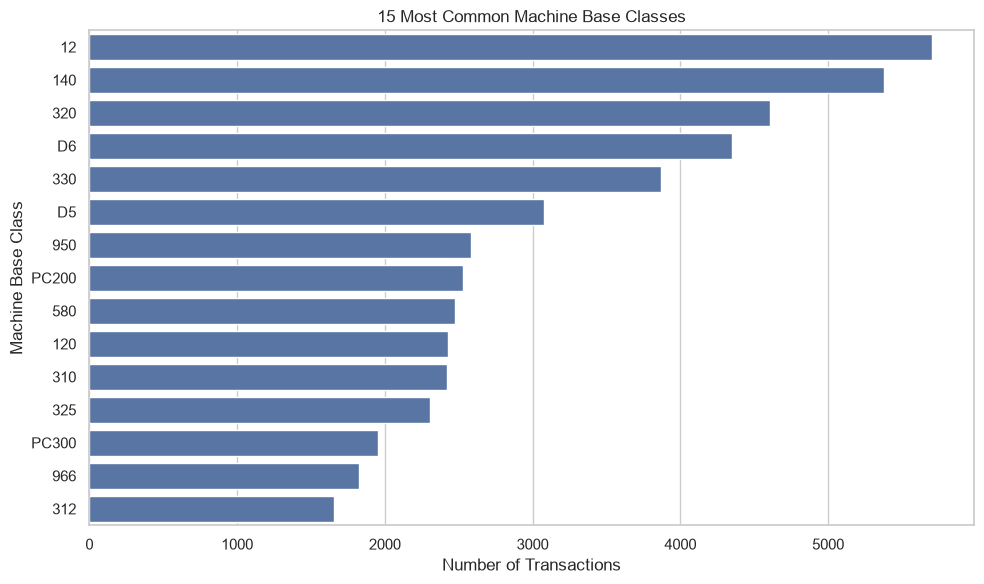

In [23]:
top_base_classes = train["Spec_BaseClass"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_base_classes.values,
    y=top_base_classes.index
)

plt.title("15 Most Common Machine Base Classes")
plt.xlabel("Number of Transactions")
plt.ylabel("Machine Base Class")
plt.tight_layout()
plt.show()

**Observations**

- Base classes `12`, `140`, and `320` are the most frequent in the dataset.
- The number of transactions varies considerably across base classes, with some appearing much more often than others.


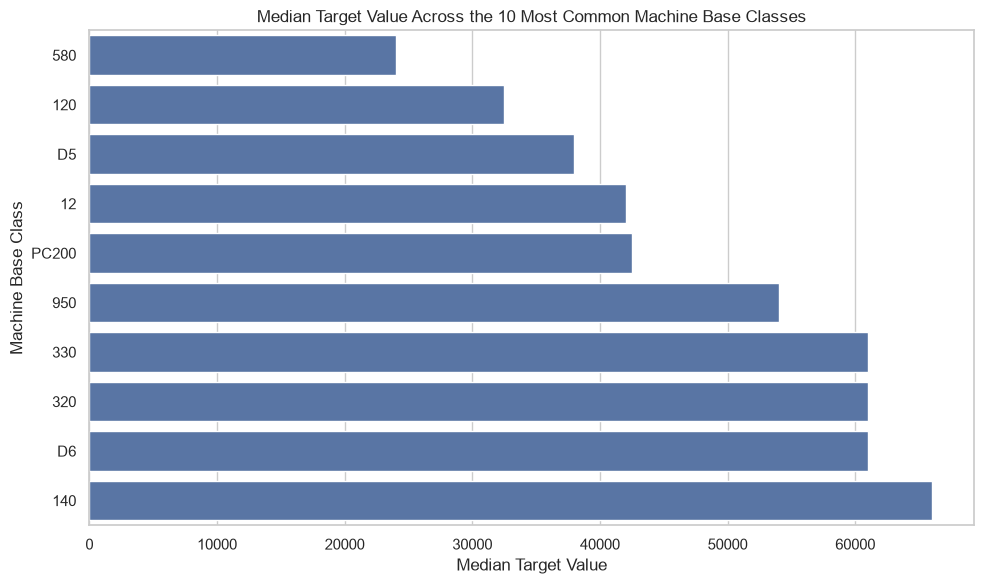

In [24]:
top_base_classes = train["Spec_BaseClass"].value_counts().head(10).index

base_class_prices = (
    train[train["Spec_BaseClass"].isin(top_base_classes)]
    .groupby("Spec_BaseClass")["TargetValue"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=base_class_prices.values,
    y=base_class_prices.index
)

plt.title("Median Target Value Across the 10 Most Common Machine Base Classes")
plt.xlabel("Median Target Value")
plt.ylabel("Machine Base Class")
plt.tight_layout()
plt.show()

**Observations**

- Base class `140` has the highest median target value, at approximately 66,000.
- Base classes `320`, `D6`, and `330` also have high median values, around 61,000.
- Base classes `580` and `120` have comparatively low median values.
- The differences in median target values suggest that `Spec_BaseClass` may be useful for predicting machinery transaction values.

### 4.6 Correlation Analysis

A correlation matrix helps identify linear relationships between numerical features and the target variable. Identifier columns are excluded because their numeric values do not necessarily represent meaningful quantities.

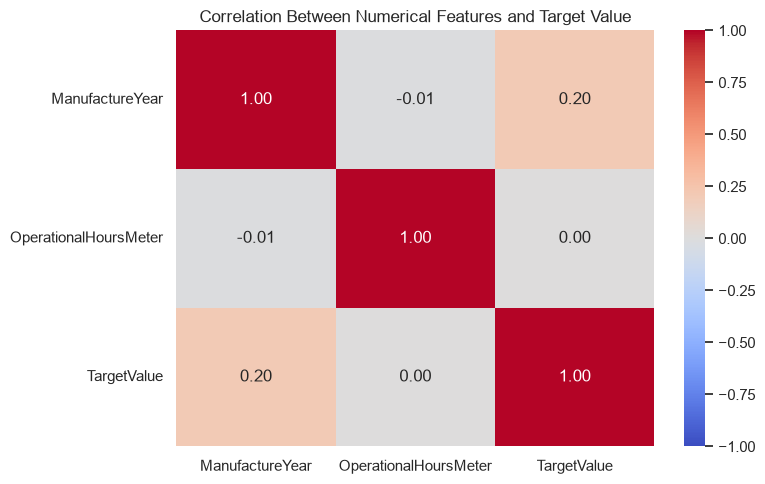

In [25]:
numerical_cols = [
    "ManufactureYear",
    "OperationalHoursMeter",
    "TargetValue"
]

correlation_matrix = train[numerical_cols].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features and Target Value")
plt.tight_layout()
plt.show()

**Observations**

- `ManufactureYear` has a weak positive correlation (0.20) with `TargetValue`, suggesting that newer machines tend to have somewhat higher transaction values.
- `OperationalHoursMeter` has almost zero linear correlation with `TargetValue` (0.00).
- The two numerical features have almost no correlation with each other (-0.01).

## 5. Data Preprocessing

In this section, we prepare the training and test datasets for machine learning. We will handle missing values, investigate anomalous values, encode categorical features, and prepare the features and target for model training while keeping the test data separate from model fitting.

### 5.1 Missing-Value Analysis

Before preprocessing the data, we examine missing values in the training and test datasets to identify affected columns and determine suitable imputation strategies.

In [ ]:
missing_values = pd.DataFrame({
    "Train Missing": train.isnull().sum(),
    "Train Missing (%)": (train.isnull().mean() * 100).round(2),
    "Test Missing": test.isnull().sum(),
    "Test Missing (%)": (test.isnull().mean() * 100).round(2)
})

missing_values = missing_values[
    (missing_values["Train Missing"] + missing_values["Test Missing"]) > 0
].sort_values("Train Missing (%)", ascending=False)

display(missing_values)

,Train Missing,Train Missing (%),Test Missing,Test Missing (%)
col18,138635,99.95,14986.0,99.91
col19,138635,99.95,14986.0,99.91
col5,128320,92.52,13878.0,92.52
col4,128320,92.52,13878.0,92.52
col27,123742,89.21,13439.0,89.59
col28,123742,89.21,13439.0,89.59
col30,119829,86.39,13041.0,86.94
col29,119829,86.39,13041.0,86.94
col8,115296,83.13,12422.0,82.81
col11,115296,83.13,12422.0,82.81


The missing-value analysis shows that several features contain a high proportion of missing values, while others have moderate levels of missingness. The patterns are broadly similar in the training and test datasets.

Features with extensive missing values will be reviewed alongside their descriptions and predictive relevance before deciding whether to retain or remove them. We can handle the missing values in the remaining numerical and categorical features during  pipeline construction.

### 5.2 Handling Anomalous Values

Before preprocessing, we examine the dataset for anomalous or implausible values across relevant features. This includes checking numerical ranges, extreme observations, inconsistent categorical labels, and suspicious values identified during exploratory data analysis.

Potential anomalies will be investigated using the feature descriptions and data distributions. Values will only be corrected, treated as missing, or removed when justified, preserving the original datasets wherever possible.

In [ ]:
numerical_features = train.select_dtypes(include="number").columns.drop(
    "TargetValue", errors="ignore"
)

numerical_summary = pd.DataFrame({
    "Train Min": train[numerical_features].min(),
    "Train Max": train[numerical_features].max(),
    "Train Zeros": (train[numerical_features] == 0).sum(),
    "Train Negative": (train[numerical_features] < 0).sum(),
    "Test Min": test.reindex(columns=numerical_features).min(),
    "Test Max": test.reindex(columns=numerical_features).max()
})

display(numerical_summary)

,Train Min,Train Max,Train Zeros,Train Negative,Test Min,Test Max
TransactionID,1139309.0,6333410.0,0,0,1139307.0,6333397.0
AssetID,8.0,2478476.0,0,0,174.0,2484757.0
ProductConfigID,39.0,37209.0,0,0,39.0,37208.0
ManufactureYear,1001.0,2015.0,0,0,1001.0,2015.0
OperationalHoursMeter,0.0,1729600.0,31583,0,0.0,932000.0


In [ ]:
categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns

categorical_summary = pd.DataFrame({
    "Unique Values": train[categorical_features].nunique(),
    "Missing Values": train[categorical_features].isnull().sum(),
    "Most Frequent Value": train[categorical_features].mode().iloc[0],
    "Most Frequent Count": train[categorical_features].apply(
        lambda col: col.value_counts().iloc[0] if col.notna().any() else 0
    )
})

display(categorical_summary.sort_values("Unique Values", ascending=False))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3988\2676982491.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train.select_dtypes(


,Unique Values,Missing Values,Most Frequent Value,Most Frequent Count
TransactionDate,3676,0,2010-02-16,1159
Spec_FullDescriptor,3505,0,140G,3751
Spec_BaseClass,1249,0,12,5702
Spec_SubClass,147,36985,G,17381
Spec_VariantModifier,132,86369,L,14496
Spec_ReleaseSeries,113,105805,II,8425
FunctionalClassification,65,0,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",11158
RegionCode,53,0,Florida,23460
VendorPartnerID,31,0,UJF,67828
col22,27,67683,None or Unspecified,54059


### 5.3 Removing Irrelevant Columns

We review identifier columns and other features that may not provide useful predictive information. Columns will be removed only when there is a clear justification, while potentially useful machine specifications and categorical features will be retained.

In [ ]:
print("Identifier columns:")
display(
    train[["TransactionID", "AssetID", "ProductConfigID"]].head()
)

print("\nUnique values in identifier columns:")
display(
    train[["TransactionID", "AssetID", "ProductConfigID"]].nunique()
)

Identifier columns:


,TransactionID,AssetID,ProductConfigID
0,1139309,117665,88
1,1139316,1001282,4616
2,1139317,772709,1948
3,1139322,902010,3550
4,1139333,1036259,36014



Unique values in identifier columns:


TransactionID      138701
AssetID            120111
ProductConfigID      3594
dtype: int64

In [ ]:
columns_to_drop = ["TransactionID","AssetID","col18", "col19"]

train = train.drop(columns=columns_to_drop)
test = test.drop(columns=columns_to_drop)

In [ ]:
for df in [train, test]:
    df.loc[df["ManufactureYear"] == 1001, "ManufactureYear"] = np.nan

### 5.4 Feature Engineering

Feature engineering creates additional features from existing data to help the model capture useful patterns. We extract the transaction year and month from `TransactionDate` and calculate the machine's age at the time of the transaction.

In [ ]:
# Convert transaction dates to datetime
train["TransactionDate"] = pd.to_datetime(train["TransactionDate"])
test["TransactionDate"] = pd.to_datetime(test["TransactionDate"])

# Extract transaction year 
train["TransactionYear"] = train["TransactionDate"].dt.year
test["TransactionYear"] = test["TransactionDate"].dt.year


# Calculate vehicle age at the time of transaction
train["VehicleAge"] = train["TransactionYear"] - train["ManufactureYear"]
test["VehicleAge"] = test["TransactionYear"] - test["ManufactureYear"]

# Treat negative ages as invalid
train.loc[train["VehicleAge"] < 0, "VehicleAge"] = np.nan
test.loc[test["VehicleAge"] < 0, "VehicleAge"] = np.nan

# Drop the original transaction date
train.drop(columns=["TransactionDate"], inplace=True)
test.drop(columns=["TransactionDate"], inplace=True)

### 5.5 Preparing Features and Target

We separate the target variable, `TargetValue`, from the input features. We then create a training and validation split to evaluate models on unseen data. The test dataset will remain separate until final prediction generation.

In [ ]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=["TargetValue"])
y = np.log1p(train["TargetValue"])

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10
)

X_test = test.copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Training features: (110960, 46)
Validation features: (27741, 46)
Test features: (15000, 46)


### 5.6 Building the Preprocessing Pipeline

We build a preprocessing pipeline to handle missing values and convert categorical features into a numerical format suitable for machine learning. The preprocessing steps will be fitted only on the training split and then applied consistently to the validation and test datasets to prevent data leakage.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", X_train.shape[1])

Numerical features: 5
Categorical features: 41
Total input features: 46


## 6. Model Building and Evaluation

We train and compare multiple regression models to predict heavy machinery transaction values. All models use the same training and validation split and preprocessing pipeline to ensure a fair comparison. Model performance is evaluated using RMLSE

### 6.1 Linear Regression

Linear Regression serves as our initial benchmark. It models the relationship between input features and transaction value using a linear combination of the features.

In [ ]:
print("y_train range:", y_train.min(), "to", y_train.max())
print("y_val range:", y_val.min(), "to", y_val.max())

y_train range: 8.922791623969637 to 11.863589378812122
y_val range: 8.922791623969637 to 11.856522261533737


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train using the log-transformed target
linear_model.fit(X_train, y_train)

# Predict in log space, then return to the original scale
y_pred_log = linear_model.predict(X_val)
y_pred = np.maximum(np.expm1(y_pred_log), 0)

# Convert actual validation targets back to the original scale
y_val_original = np.expm1(y_val)

# Evaluate on the original target scale
rmsle = root_mean_squared_log_error(y_val_original, y_pred)

print(f"Linear Regression RMSLE: {rmsle:.4f}")


Linear Regression RMSLE: 0.3545


### 6.2 Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear relationships between machine characteristics and transaction values, making it suitable for this regression task.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_log = random_forest_model.predict(X_val)
y_pred = np.maximum(np.expm1(y_pred_log), 0)

y_val_original = np.expm1(y_val)
rmsle = root_mean_squared_log_error(y_val_original, y_pred)

print(f"Random Forest RMSLE: {rmsle:.4f}")

Random Forest RMSLE: 0.2261


#### 6.2.1 Random Forest Hyperparameter Tuning

We tune selected Random Forest hyperparameters to investigate whether changing the number of trees, tree depth, and minimum samples required for a split can improve validation RMSLE.

In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.8, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_root_mean_squared_log_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf_model = rf_search.best_estimator_


y_pred_log = best_rf_model.predict(X_val)

y_pred = np.maximum(np.expm1(y_pred_log), 0)
y_val_original = np.expm1(y_val)

# Evaluate using RMSLE on the original scale
rmsle = root_mean_squared_log_error(y_val_original, y_pred)

print(f"Tuned Random Forest RMSLE: {rmsle:.4f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Tuned Random Forest RMSLE: 0.2202


### 6.3 XGBoost Regressor

XGBoost is a gradient-boosting algorithm that builds decision trees sequentially, with each new tree helping correct errors made by the existing model. It is often effective on structured/tabular datasets.

We use GPU acceleration to speed up training where supported and evaluate performance using RMSLE.

In [ ]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import xgboost as xgb
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

print("XGBoost version:", xgb.__version__)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb.XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        device="cuda",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

y_pred_log = xgb_model.predict(X_val)

y_pred = np.maximum(np.expm1(y_pred_log), 0)
y_val_original = np.expm1(y_val)

rmsle = root_mean_squared_log_error(y_val_original, y_pred)

print(f"XGBoost RMSLE: {rmsle:.4f}")

XGBoost version: 3.3.0
XGBoost RMSLE: 0.2326


#### 6.3.1 XGBoost Hyperparameter Tuning

We tune selected XGBoost hyperparameters using cross-validation and RMSLE-based scoring. The best configuration is then evaluated on the same validation set used for the other models.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
import numpy as np

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        device="cuda",
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": [300, 500, 700],
    "model__max_depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_root_mean_squared_log_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

best_xgb_model = xgb_search.best_estimator_


# Predict on the validation set (log-transformed scale)
y_pred_log = best_xgb_model.predict(X_val)

# Convert predictions and actual values to the original scale
y_pred = np.maximum(np.expm1(y_pred_log), 0)
y_val_original = np.expm1(y_val)

# Evaluate using RMSLE on the original target scale
rmsle = root_mean_squared_log_error(y_val_original, y_pred)

print("Best parameters:", xgb_search.best_params_)
print(f"Tuned XGBoost RMSLE: {rmsle:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__subsample': 1.0, 'model__n_estimators': 500, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}
Tuned XGBoost RMSLE: 0.2370


**Observation:**

Increasing the number of cross-validation folds does not necessarily improve model performance. More folds can provide a more reliable estimate of performance, but the final RMSLE depends on the model and its hyperparameters.

### 6.4 CatBoost Regressor

CatBoost is a gradient-boosting algorithm that is particularly effective on datasets containing categorical features. It provides native categorical-feature handling, although our current preprocessing pipeline already encodes categorical features. We will first evaluate CatBoost using our existing preprocessing pipeline and validation split, then consider hyperparameter tuning if the results justify it.

In [64]:
from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_log_error
import numpy as np
import pandas as pd

# Work on copies to avoid modifying the original data
X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

# Detect categorical columns from the training split
cat_features_cb = X_train_cb.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Handle missing categorical values consistently
for col in cat_features_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("Missing").astype(str)

# Train CatBoost on the log-transformed target
catboost_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=200,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features_cb
)

# Predict in log space and convert back to the original scale
y_pred_log = catboost_model.predict(X_val_cb)
y_pred = np.maximum(np.expm1(y_pred_log), 0)

# Evaluate using RMSLE on the original target
catboost_rmsle = root_mean_squared_log_error(
    np.expm1(y_val),
    y_pred
)

print(f"CatBoost RMSLE: {catboost_rmsle:.4f}")

0:	learn: 0.6483231	total: 176ms	remaining: 2m 55s
200:	learn: 0.2465703	total: 38s	remaining: 2m 31s
400:	learn: 0.2299717	total: 1m 16s	remaining: 1m 54s
600:	learn: 0.2221434	total: 1m 57s	remaining: 1m 18s
800:	learn: 0.2167975	total: 2m 39s	remaining: 39.5s
999:	learn: 0.2132622	total: 3m 20s	remaining: 0us
CatBoost RMSLE: 0.2168


### 6.4.1 — CatBoost Hyperparameter Tuning

In [65]:
from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import root_mean_squared_log_error
import numpy as np

# Work on copies to preserve the original datasets
X_train_cb = X_train.copy()
X_val_cb = X_val.copy()

# Identify categorical columns
cat_features_cb = X_train_cb.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# CatBoost requires categorical values to be strings or consistently typed
for col in cat_features_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("Missing").astype(str)

# CatBoost model with native categorical handling
catboost_model = CatBoostRegressor(
    loss_function="RMSE",
    task_type="GPU",
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

# Hyperparameter search space
catboost_params = {
    "iterations": [1000, 2000, 3000,5000],
    "depth": [6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7]
}

catboost_search = RandomizedSearchCV(
    estimator=catboost_model,
    param_distributions=catboost_params,
    n_iter=8,
    scoring="neg_root_mean_squared_log_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=200,
    error_score="raise"
)

# Tune on the log-transformed target
catboost_search.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features_cb
)

best_catboost_model = catboost_search.best_estimator_

# Predict on the validation set
y_pred_catboost_log = best_catboost_model.predict(X_val_cb)

# Convert predictions and actual values back to original scale
y_pred_catboost = np.maximum(np.expm1(y_pred_catboost_log), 0)
y_val_original = np.expm1(y_val)

# Evaluate using RMSLE on the original target scale
catboost_tuned_rmsle = root_mean_squared_log_error(
    y_val_original,
    y_pred_catboost
)

print("Best parameters:", catboost_search.best_params_)
print(f"Tuned CatBoost RMSLE: {catboost_tuned_rmsle:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV 1/3; 1/8] START depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1.
[CV 1/3; 1/8] END depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1;, score=-0.019 total time= 1.6min
[CV 2/3; 1/8] START depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1.
[CV 2/3; 1/8] END depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1;, score=-0.019 total time= 1.6min
[CV 3/3; 1/8] START depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1.
[CV 3/3; 1/8] END depth=10, iterations=1000, l2_leaf_reg=5, learning_rate=0.1;, score=-0.019 total time= 1.6min
[CV 1/3; 2/8] START depth=6, iterations=2000, l2_leaf_reg=3, learning_rate=0.05.
[CV 1/3; 2/8] END depth=6, iterations=2000, l2_leaf_reg=3, learning_rate=0.05;, score=-0.020 total time= 2.1min
[CV 2/3; 2/8] START depth=6, iterations=2000, l2_leaf_reg=3, learning_rate=0.05.
[CV 2/3; 2/8] END depth=6, iterations=2000, l2_leaf_reg=3, learning_rate=0.05;, score=-

## 7. Conclusion

This project developed a machine learning pipeline to predict the sale prices of heavy machinery using historical transaction data and equipment specifications.

The workflow included exploratory data analysis, missing-value handling, preprocessing, and the evaluation of multiple regression models. CatBoost was explored for its ability to handle categorical features natively, followed by hyperparameter tuning using cross-validation.

The tuned CatBoost model achieved a validation RMSLE of **0.2061**. This provides a benchmark for evaluating the model's predictive performance on unseen data.

The project demonstrates an end-to-end machine learning workflow, from understanding the dataset and preparing features to model evaluation and prediction generation. Further improvements could include more systematic feature engineering, additional hyperparameter optimization, and evaluation on alternative validation splits.